<a href="https://colab.research.google.com/github/x-nbriones/Briones-CS3B_CSST101/blob/main/CSST101_Set2_Briones_Natalie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Set 2: Student Academic Advising KRR System


Student Profile

In [62]:
students <- data.frame(
  Student_name = c("Alice", "Charlie", "Percy", "Jennie", "Evan", "Niki"),
  Grade = c(92, 63, 95, 79, 93, 70),
  Attendance = c(88, 68, 92, 88, 70, 80)
)
students

Student_name,Grade,Attendance
<chr>,<dbl>,<dbl>
Alice,92,88
Charlie,63,68
Percy,95,92
Jennie,79,88
Evan,93,70
Niki,70,80


Represent Student Records as Facts & Define the 8 IF-THEN Rules

In [60]:
evaluate_student <- function(grade, att) {

  facts <- c()

  if (att < 75) {
    facts <- c(facts, "Attendance < 75%")
  } else {
    facts <- c(facts, "Attendance >= 75%")
  }

  if (grade < 75) {
    facts <- c(facts, "Average grade < 75")
  } else {
    facts <- c(facts, "Average grade >= 75")
  }

  fired_rules <- c()
  added <- TRUE

  while (added) {
    added <- FALSE

    if (att < 75 && !("Attendance concern" %in% facts)) {
      facts <- c(facts, "Attendance concern")
      fired_rules <- c(fired_rules, "R1 - Attendance Concern")
      added <- TRUE
    }

    if (grade < 75 && !("Academic concern" %in% facts)) {
      facts <- c(facts, "Academic concern")
      fired_rules <- c(fired_rules, "R2 - Academic Concern")
      added <- TRUE
    }

    if (("Attendance concern" %in% facts) && ("Academic concern" %in% facts) && !("Priority advising" %in% facts)) {
      facts <- c(facts, "Priority advising")
      fired_rules <- c(fired_rules, "R3 - Priority Advising")
      added <- TRUE
    }

    if (("Priority advising" %in% facts) && !("Recommend adviser consultation" %in% facts)) {
      facts <- c(facts, "Recommend adviser consultation")
      fired_rules <- c(fired_rules, "R4 - Adviser Consultation")
      added <- TRUE
    }

    if (grade >= 90 && att >= 90 && !("Recognition review" %in% facts)) {
      facts <- c(facts, "Recognition review")
      fired_rules <- c(fired_rules, "R5 - Recognition Review")
      added <- TRUE
    }

    if (grade >= 75 && att >= 75 && !("Dean's list candidate" %in% facts) && grade >= 85 && att >= 85) {
      facts <- c(facts, "Dean's list candidate")
      fired_rules <- c(fired_rules, "R6 - Dean's List Candidate")
      added <- TRUE
    }

    if (("Attendance concern" %in% facts) && !("Warning notice" %in% facts)) {
      facts <- c(facts, "Warning notice")
      fired_rules <- c(fired_rules, "R7 - Warning notice")
      added <- TRUE
    }

    if (("Academic concern" %in% facts) && !("Remedial offered" %in% facts)) {
      facts <- c(facts, "Remedial offered")
      fired_rules <- c(fired_rules, "R8 - Remedial Offered")
      added <- TRUE
    }
  }

  return(list(facts = facts, rules = fired_rules))
}

Student Profile with Rules Fired

In [63]:
all_rules_fired <- sapply(1:nrow(students), function(i) {
  res <- evaluate_student(students$Grade[i], students$Attendance[i])
  if (length(res$rules) > 0) {
    return(paste(res$rules, collapse = ", "))
  } else {
    return("None")
  }
})

students_summary <- students
students_summary$Rules_Fired <- all_rules_fired

students_summary

Student_name,Grade,Attendance,Rules_Fired
<chr>,<dbl>,<dbl>,<chr>
Alice,92,88,R6 - Dean's List Candidate
Charlie,63,68,"R1 - Attendance Concern, R2 - Academic Concern, R3 - Priority Advising, R4 - Adviser Consultation, R7 - Warning notice, R8 - Remedial Offered"
Percy,95,92,"R5 - Recognition Review, R6 - Dean's List Candidate"
Jennie,79,88,None
Evan,93,70,"R1 - Attendance Concern, R7 - Warning notice"
Niki,70,80,"R2 - Academic Concern, R8 - Remedial Offered"


Testing & Rules for each profile

In [68]:
student_name <- readline("Enter Student name: ")
print(student_name)

Enter Student name: Charlie
[1] "Charlie"


In [69]:
student <- students[
  students$Student_name == student_name,
]
student

,Student_name,Grade,Attendance
,<chr>,<dbl>,<dbl>
2,Charlie,63,68


In [70]:
if (nrow(student) > 0) {
  res <- evaluate_student(student$Grade, student$Attendance)
  cat("Rules Fired:\n")
  if (length(res$rules) > 0) {
    for (r in res$rules) {
      cat(" *", r, "\n")
    }
  } else {
    cat("  None (No rules triggered)\n")
  }
} else {
  cat("Student not found.")
}

Rules Fired:
 * R1 - Attendance Concern 
 * R2 - Academic Concern 
 * R3 - Priority Advising 
 * R4 - Adviser Consultation 
 * R7 - Warning notice 
 * R8 - Remedial Offered 


Initial Facts, Inferred Conclusions & Recommendations

In [71]:
recommend_student <- function(facts) {
  if ("Priority advising" %in% facts) {
    return("Consult Academic adviser immediately")
  } else if ("Attendance concern" %in% facts || "Academic concern" %in% facts) {
    return("Complete remedial requirements before next term")
  } else {
    return("Student is in good standing and may enroll")
  }
}

res <- evaluate_student(student$Grade, student$Attendance)

student$Facts_Summary <- paste(res$facts, collapse = ", ")
student$Recommendation <- sapply(list(res$facts), recommend_student)

cat("========================================\n")
cat("ACADEMIC ADVISING REPORT FOR:", student$Student_name, "\n")
cat("----------------------------------------\n")
cat("Grade:", student$Grade, "\n")
cat("Attendance:", student$Attendance,"%\n\n")
cat("Facts & Inferred Conclusions:\n")
for (f in res$facts) {
  cat(" *", f, "\n")
}

cat("\nTriggered Rules:\n")
if (length(res$rules) > 0) {
  for (r in res$rules) {
    cat(" *", r, "\n")
  }
} else {
  cat("  None (No rules triggered)\n")
}

cat("\nRecommendation:\n", student$Recommendation, "\n")
cat("========================================\n")

ACADEMIC ADVISING REPORT FOR: Charlie 
----------------------------------------
Grade: 63 
Attendance: 68 %

Facts & Inferred Conclusions:
 * Attendance < 75% 
 * Average grade < 75 
 * Attendance concern 
 * Academic concern 
 * Priority advising 
 * Recommend adviser consultation 
 * Warning notice 
 * Remedial offered 

Triggered Rules:
 * R1 - Attendance Concern 
 * R2 - Academic Concern 
 * R3 - Priority Advising 
 * R4 - Adviser Consultation 
 * R7 - Warning notice 
 * R8 - Remedial Offered 

Recommendation:
 Consult Academic adviser immediately 


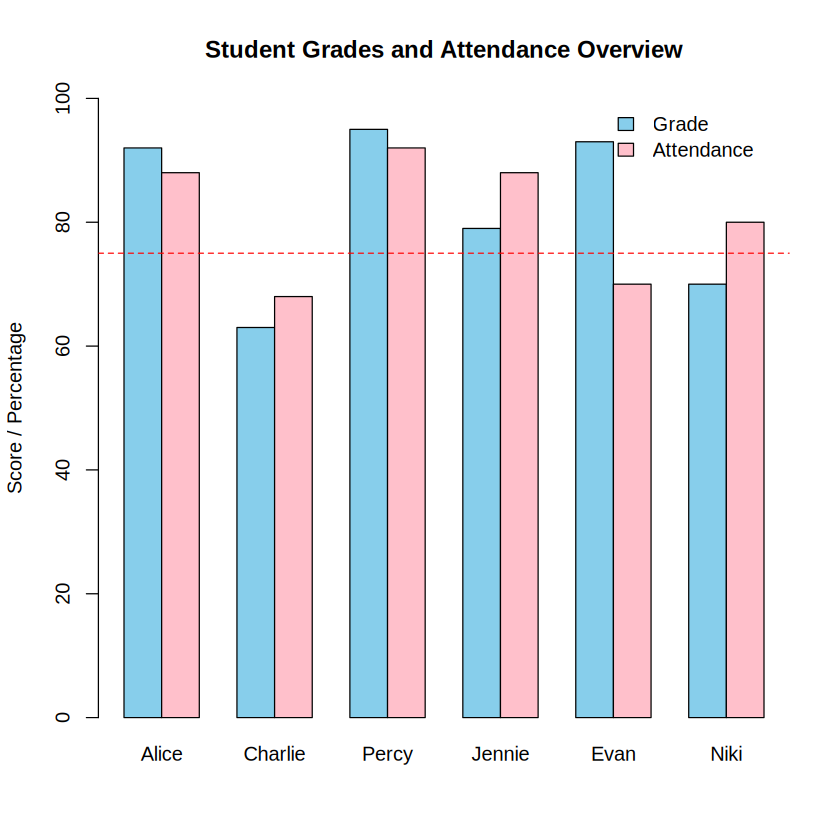

In [75]:
barplot(
  t(as.matrix(students[, c("Grade", "Attendance")])),
  beside = TRUE,
  col = c("skyblue", "pink"),
  names.arg = students$Student_name,
  main = "Student Grades and Attendance Overview",
  ylab = "Score / Percentage",
  ylim = c(0, 100),
  legend.text = c("Grade", "Attendance"),
  args.legend = list(x = "topright", bty = "n")
)

abline(h = 75, col = "red", lty = 2)